In [17]:
import numpy as np
import matplotlib.pyplot as plt
import csv

Візуалізуємо дані з lab1_train.csv

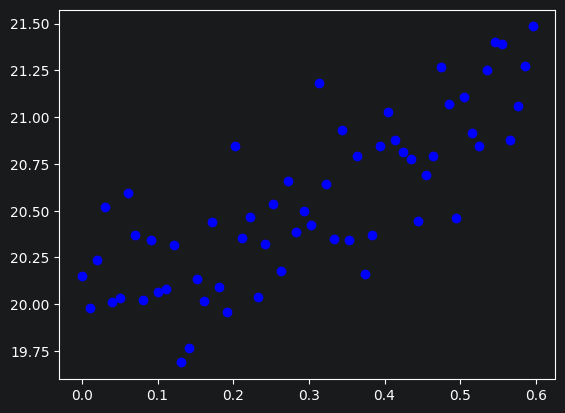

In [18]:
x_list = []
y_list = []

with open("lab_1_train.csv", "r") as train_file:
    train_data = csv.reader(train_file, delimiter=',')
    next(train_data)
    for row in train_data:
        x_list.append(float(row[1]))
        y_list.append(float(row[2]))

plt.scatter(x_list,y_list, color = 'blue')
plt.show()


In [19]:
x_arr = np.array(x_list)
y_arr = np.array(y_list)

Реалізуємо linear regression

In [20]:
def y_predict(x, w):
    return w[0] + w[1]*x

Використаємо Mean Squared Error як функцію втрат

In [21]:
def cost_function(x, y, w):
    n = len(x)
    residual = y - y_predict(x, w)
    return (1/n)* sum(np.pow(residual,2))


In [22]:
def dJ_dw0(x, y, w):
    n = len(x)
    residual = y - y_predict(x, w)
    return (-2/n)* sum(residual)

def dJ_dw1(x , y, w):
    n = len(x)
    residual = y - y_predict(x, w)
    return (-2/n)* sum(x*residual)

In [23]:
def gradient_descent(start_w, learning_rate, x,y):
    eps = 0.01
    epoches = 0
    while eps > 1e-6:
        cost_func = cost_function(x, y, start_w)
        print(f"Epoch_No: {epoches}")
        print("Cost function", cost_func)
        w0_new = start_w[0] - learning_rate*dJ_dw0(x, y, start_w)
        w1_new = start_w[1] - learning_rate*dJ_dw1(x, y, start_w)
        start_w = (w0_new, w1_new)
        cost_func_new = cost_function(x, y, start_w)
        print("W0_new: ",w0_new)
        print("W1_new",w1_new)
        print("New cost function: ",cost_func_new)
        eps = abs(cost_func - cost_func_new)
        if epoches == 10000:
            break
        else:
            epoches += 1

    return start_w, cost_func, epoches



In [24]:
values = [0,0]
a = 0.01

In [25]:
weights, cost_f, epo = gradient_descent(values, a, x_arr, y_arr)

Epoch_No: 0
Cost function 422.47740188480697
W0_new:  0.41099126382076906
W1_new 0.12367813465364869
New cost function:  404.2574249767672
Epoch_No: 1
Cost function 404.2574249767672
W0_new:  0.8130256306535506
W1_new 0.24461160240278607
New cost function:  386.82412434421605
Epoch_No: 2
Cost function 386.82412434421605
W0_new:  1.2062985955438985
W1_new 0.3628603365917162
New cost function:  370.14353312529073
Epoch_No: 3
Cost function 370.14353312529073
W0_new:  1.59100138645794
W1_new 0.4784829623813285
New cost function:  354.1831510696294
Epoch_No: 4
Cost function 354.1831510696294
W0_new:  1.967321057420207
W1_new 0.5915368253029152
New cost function:  338.91188121343606
Epoch_No: 5
Cost function 338.91188121343606
W0_new:  2.335440579618544
W1_new 0.7020780191887422
New cost function:  324.2999692887721
Epoch_No: 6
Cost function 324.2999692887721
W0_new:  2.695538930520464
W1_new 0.8101614134929777
New cost function:  310.3189457490135
Epoch_No: 7
Cost function 310.3189457490135

In [26]:
print("Weights: ", weights)
print("Cost: ", cost_f)
print("Epoches: ", epo)

Weights:  (np.float64(19.90770025173107), np.float64(2.149134267690963))
Cost:  0.07392620726422039
Epoches:  5528


In [27]:
result = y_predict(x_arr, weights)

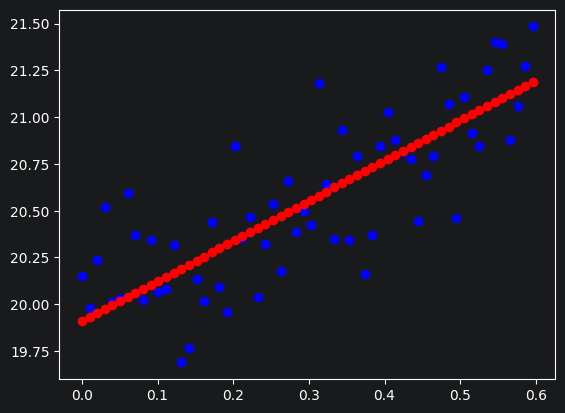

In [28]:
plt.plot(x_arr, result, 'ro')
plt.scatter(x_arr,y_arr, color = 'blue')
plt.show()

In [29]:
x_list_test = []
y_list_test = []

with open("lab_1_test.csv", "r") as train_file:
    train_data = csv.reader(train_file, delimiter=',')
    next(train_data)
    for row in train_data:
        x_list_test.append(float(row[1]))
        y_list_test.append(float(row[2]))


In [30]:
x_arr_test = np.array(x_list_test)
y_arr_test = np.array(y_list_test)

Порахуємо функцію втрат на тестових даних з lab1_test.csv.


In [31]:
cost_func_test = cost_function(x_arr_test, y_arr_test, weights)
print("Cost function (test_data) = ", cost_func_test)

Cost function (test_data) =  0.07538391086484146


Візуалізуємо на одному графіку дані з lab1_train.csv,  lab1_test.csv та лінію, до якої зійшовся розв’язок


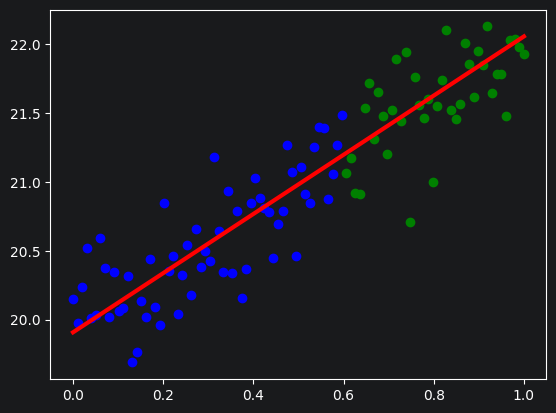

In [32]:
x_line = np.linspace(x_arr.min(), x_arr_test.max(), 100)

y_line = y_predict(x_line, weights)

plt.plot(x_line, y_line, linewidth = '3', color = 'red')
plt.scatter(x_arr,y_arr, color = 'blue')
plt.scatter(x_list_test,y_list_test, color = 'green')
plt.show()